In [ ]:
# Implementation of Moving Average and Exponential Smoothing Forecasting

import pandas as pd
import matplotlib.pyplot as plt

# Create a small monthly sales dataset
data = {
    "Month": pd.date_range(start="2025-01-01", periods=12, freq="MS"),
    "Sales": [120, 135, 128, 145, 150, 160, 155, 170, 168, 180, 190, 185]
}

df = pd.DataFrame(data)

print(df)

# Plot the original sales series
plt.figure(figsize=(10, 5))
plt.plot(df["Month"], df["Sales"], marker="o")
plt.title("Monthly Sales")
plt.xlabel("Month")
plt.ylabel("Sales")
plt.grid(True)
plt.show()

# -------------------------------
# 1. Moving Average Forecasting
# -------------------------------

window = 3

df["Moving_Average"] = df["Sales"].rolling(window=window).mean()

print("\n3-Month Moving Average:")
print(df[["Month", "Sales", "Moving_Average"]])

# Forecast the next month using the latest 3 observations
ma_forecast = df["Sales"].tail(window).mean()
print("\nMoving Average Forecast for next month:", round(ma_forecast, 2))

# Plot actual sales and moving average
plt.figure(figsize=(10, 5))
plt.plot(df["Month"], df["Sales"], marker="o", label="Actual Sales")
plt.plot(df["Month"], df["Moving_Average"], marker="o", label="3-Month Moving Average")
plt.title("Moving Average Smoothing")
plt.xlabel("Month")
plt.ylabel("Sales")
plt.legend()
plt.grid(True)
plt.show()

# -------------------------------
# 2. Simple Exponential Smoothing
# -------------------------------

from statsmodels.tsa.holtwinters import SimpleExpSmoothing

model = SimpleExpSmoothing(df["Sales"], initialization_method="estimated")
fit = model.fit(optimized=True)

df["SES_Fitted"] = fit.fittedvalues

# Forecast the next month
ses_forecast = fit.forecast(1)

print("\nSimple Exponential Smoothing:")
print(df[["Month", "Sales", "SES_Fitted"]])
print("\nSES Forecast for next month:", round(float(ses_forecast.iloc[0]), 2))

# Plot actual sales and exponential smoothing
plt.figure(figsize=(10, 5))
plt.plot(df["Month"], df["Sales"], marker="o", label="Actual Sales")
plt.plot(df["Month"], df["SES_Fitted"], marker="o", label="Exponential Smoothing")
plt.title("Simple Exponential Smoothing")
plt.xlabel("Month")
plt.ylabel("Sales")
plt.legend()
plt.grid(True)
plt.show()

# -------------------------------
# 3. Compare the forecasts
# -------------------------------

print("\nForecast Comparison")
print("3-Month Moving Average:", round(ma_forecast, 2))
print("Simple Exponential Smoothing:", round(float(ses_forecast.iloc[0]), 2))

        Month  Sales
0  2025-01-01    120
1  2025-02-01    135
2  2025-03-01    128
3  2025-04-01    145
4  2025-05-01    150
5  2025-06-01    160
6  2025-07-01    155
7  2025-08-01    170
8  2025-09-01    168
9  2025-10-01    180
10 2025-11-01    190
11 2025-12-01    185


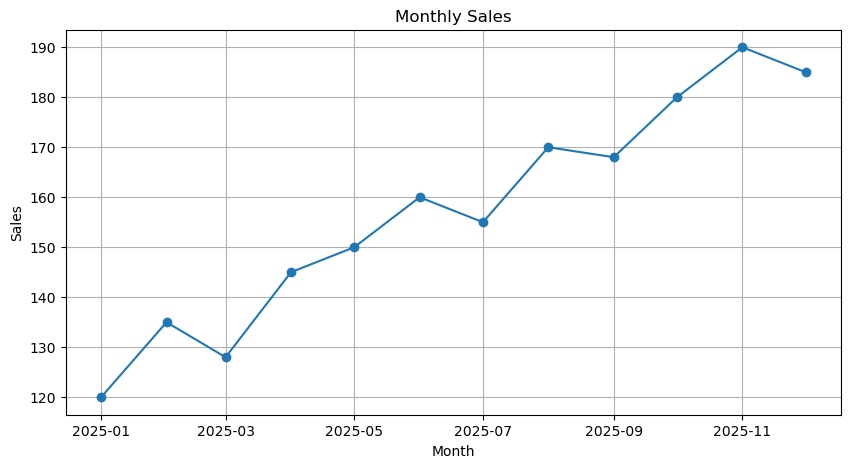


3-Month Moving Average:
        Month  Sales  Moving_Average
0  2025-01-01    120             NaN
1  2025-02-01    135             NaN
2  2025-03-01    128      127.666667
3  2025-04-01    145      136.000000
4  2025-05-01    150      141.000000
5  2025-06-01    160      151.666667
6  2025-07-01    155      155.000000
7  2025-08-01    170      161.666667
8  2025-09-01    168      164.333333
9  2025-10-01    180      172.666667
10 2025-11-01    190      179.333333
11 2025-12-01    185      185.000000

Moving Average Forecast for next month: 185.0


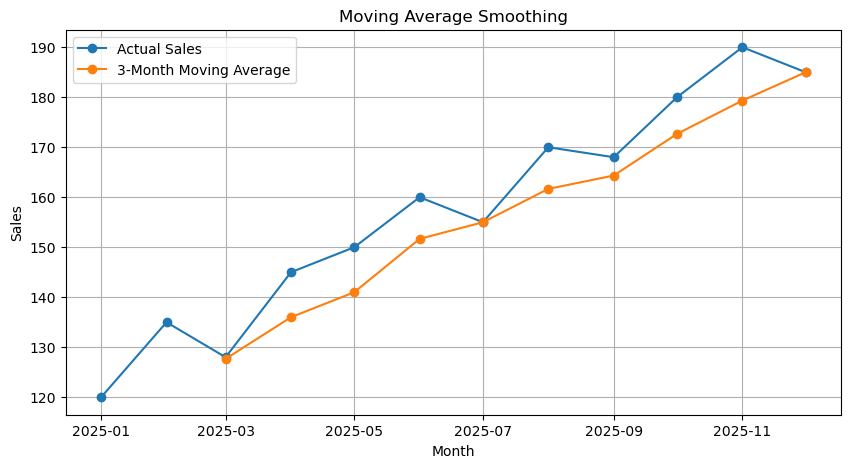


Simple Exponential Smoothing:
        Month  Sales  SES_Fitted
0  2025-01-01    120  121.273165
1  2025-02-01    135  120.111618
2  2025-03-01    128  133.694736
3  2025-04-01    145  128.499257
4  2025-05-01    150  143.553380
5  2025-06-01    160  149.434825
6  2025-07-01    155  159.073751
7  2025-08-01    170  155.357146
8  2025-09-01    168  168.716261
9  2025-10-01    180  168.062795
10 2025-11-01    190  178.953466
11 2025-12-01    185  189.031551

SES Forecast for next month: 185.35


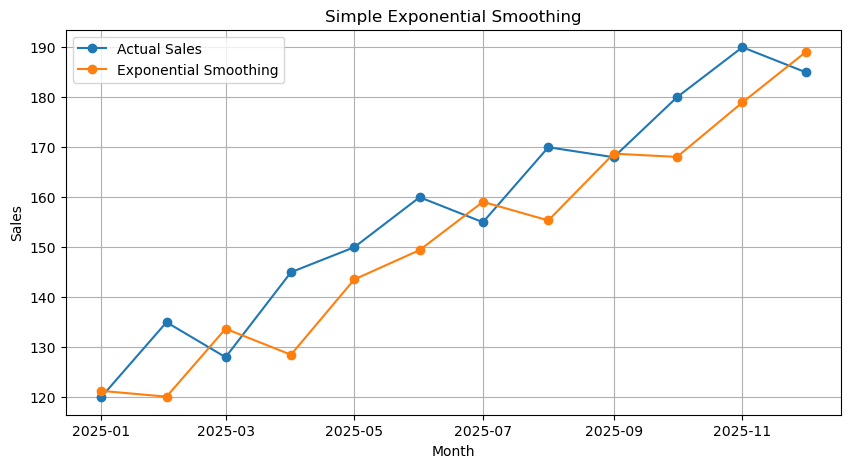


Forecast Comparison
3-Month Moving Average: 185.0
Simple Exponential Smoothing: 185.35


       Month  Sales
0 2025-01-01    200
1 2025-02-01    220
2 2025-03-01    210
3 2025-04-01    240
4 2025-05-01    250
5 2025-06-01    270
6 2025-07-01    260
7 2025-08-01    280

3-Month Moving Average:
       Month  Sales  Moving_Average
0 2025-01-01    200             NaN
1 2025-02-01    220             NaN
2 2025-03-01    210      210.000000
3 2025-04-01    240      223.333333
4 2025-05-01    250      233.333333
5 2025-06-01    270      253.333333
6 2025-07-01    260      260.000000
7 2025-08-01    280      270.000000

Moving Average Forecast for next month: 270.0


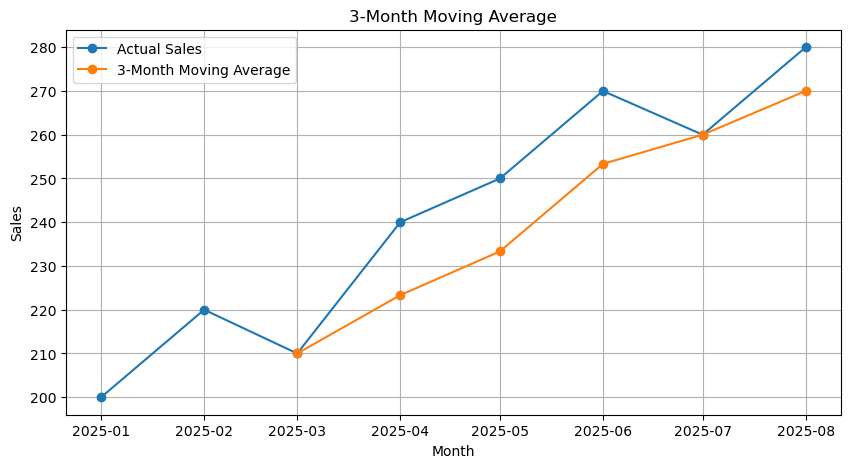

In [2]:
# Practice Problem 1 — Moving Average

import pandas as pd
import matplotlib.pyplot as plt

# Create monthly sales dataset
data = {
    "Month": pd.date_range(start="2025-01-01", periods=8, freq="MS"),
    "Sales": [200, 220, 210, 240, 250, 270, 260, 280]
}

df = pd.DataFrame(data)

print(df)

# Calculate 3-month moving average
window = 3

df["Moving_Average"] = df["Sales"].rolling(window=window).mean()

print("\n3-Month Moving Average:")
print(df[["Month", "Sales", "Moving_Average"]])

# Forecast the next month using the latest 3 observations
ma_forecast = df["Sales"].tail(window).mean()

print("\nMoving Average Forecast for next month:",
      round(ma_forecast, 2))

# Plot actual sales and moving average
plt.figure(figsize=(10, 5))
plt.plot(df["Month"], df["Sales"],
         marker="o", label="Actual Sales")
plt.plot(df["Month"], df["Moving_Average"],
         marker="o", label="3-Month Moving Average")

plt.title("3-Month Moving Average")
plt.xlabel("Month")
plt.ylabel("Sales")
plt.legend()
plt.grid(True)
plt.show()


       Month  Sales
0 2025-01-01    200
1 2025-02-01    220
2 2025-03-01    210
3 2025-04-01    240
4 2025-05-01    250
5 2025-06-01    270
6 2025-07-01    260
7 2025-08-01    280

3-Month and 5-Month Moving Average:
       Month  Sales  Moving_Average_3  Moving_Average_5
0 2025-01-01    200               NaN               NaN
1 2025-02-01    220               NaN               NaN
2 2025-03-01    210        210.000000               NaN
3 2025-04-01    240        223.333333               NaN
4 2025-05-01    250        233.333333             224.0
5 2025-06-01    270        253.333333             238.0
6 2025-07-01    260        260.000000             246.0
7 2025-08-01    280        270.000000             260.0


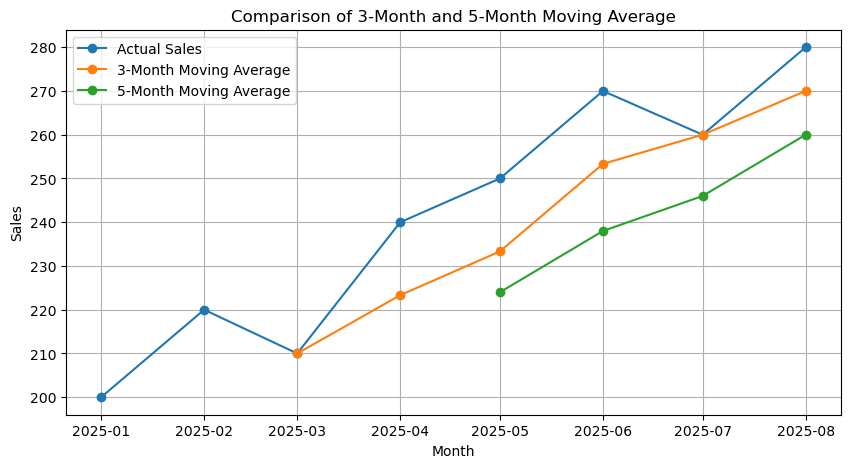

In [3]:
# Practice Problem 2 — Compare Window Sizes

import pandas as pd
import matplotlib.pyplot as plt

# Create monthly sales dataset
data = {
    "Month": pd.date_range(start="2025-01-01", periods=8, freq="MS"),
    "Sales": [200, 220, 210, 240, 250, 270, 260, 280]
}

df = pd.DataFrame(data)

print(df)

# Calculate 3-month moving average
df["Moving_Average_3"] = df["Sales"].rolling(window=3).mean()

# Calculate 5-month moving average
df["Moving_Average_5"] = df["Sales"].rolling(window=5).mean()

print("\n3-Month and 5-Month Moving Average:")
print(df[["Month", "Sales", "Moving_Average_3", "Moving_Average_5"]])

# Plot actual sales and both moving averages
plt.figure(figsize=(10, 5))
plt.plot(df["Month"], df["Sales"],
         marker="o", label="Actual Sales")
plt.plot(df["Month"], df["Moving_Average_3"],
         marker="o", label="3-Month Moving Average")
plt.plot(df["Month"], df["Moving_Average_5"],
         marker="o", label="5-Month Moving Average")

plt.title("Comparison of 3-Month and 5-Month Moving Average")
plt.xlabel("Month")
plt.ylabel("Sales")
plt.legend()
plt.grid(True)
plt.show()

In [5]:
# The 5-month moving average is smoother than the 3-month moving average because it uses more observations to calculate each average. However, the 5-month moving average responds more slowly to recent changes in sales.

       Month  Sales
0 2025-01-01    150
1 2025-02-01    160
2 2025-03-01    155
3 2025-04-01    170
4 2025-05-01    180
5 2025-06-01    175
6 2025-07-01    190
7 2025-08-01    200

Simple Exponential Smoothing:
       Month  Sales  SES_Fitted
0 2025-01-01    150       150.0
1 2025-02-01    160       150.0
2 2025-03-01    155       160.0
3 2025-04-01    170       155.0
4 2025-05-01    180       170.0
5 2025-06-01    175       180.0
6 2025-07-01    190       175.0
7 2025-08-01    200       190.0

SES Forecast for next month: 200.0


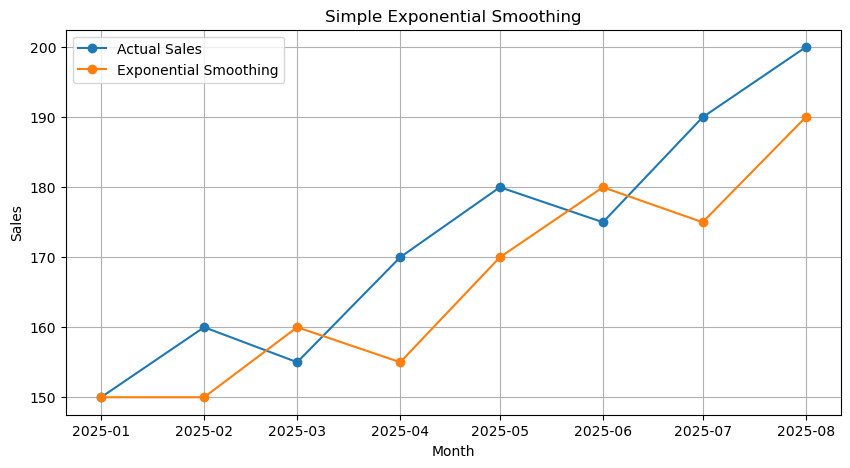

In [6]:
# Practice Problem 3 — Exponential Smoothing

import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.holtwinters import SimpleExpSmoothing

# Create sales dataset
data = {
    "Month": pd.date_range(start="2025-01-01", periods=8, freq="MS"),
    "Sales": [150, 160, 155, 170, 180, 175, 190, 200]
}

df = pd.DataFrame(data)

print(df)

# Apply Simple Exponential Smoothing
model = SimpleExpSmoothing(
    df["Sales"],
    initialization_method="estimated"
)

fit = model.fit(optimized=True)

# Display fitted values
df["SES_Fitted"] = fit.fittedvalues

print("\nSimple Exponential Smoothing:")
print(df[["Month", "Sales", "SES_Fitted"]])

# Forecast the next month
ses_forecast = fit.forecast(1)

print("\nSES Forecast for next month:",
      round(float(ses_forecast.iloc[0]), 2))

# Plot actual sales and exponential smoothing
plt.figure(figsize=(10, 5))
plt.plot(df["Month"], df["Sales"],
         marker="o", label="Actual Sales")
plt.plot(df["Month"], df["SES_Fitted"],
         marker="o", label="Exponential Smoothing")

plt.title("Simple Exponential Smoothing")
plt.xlabel("Month")
plt.ylabel("Sales")
plt.legend()
plt.grid(True)
plt.show()

       Month  Sales
0 2025-01-01    100
1 2025-02-01    120
2 2025-03-01    115
3 2025-04-01    130
4 2025-05-01    145
5 2025-06-01    140
6 2025-07-01    155
7 2025-08-01    170
8 2025-09-01    165
9 2025-10-01    180

3-Month Moving Average:
       Month  Sales  Moving_Average
0 2025-01-01    100             NaN
1 2025-02-01    120             NaN
2 2025-03-01    115      111.666667
3 2025-04-01    130      121.666667
4 2025-05-01    145      130.000000
5 2025-06-01    140      138.333333
6 2025-07-01    155      146.666667
7 2025-08-01    170      155.000000
8 2025-09-01    165      163.333333
9 2025-10-01    180      171.666667

Moving Average Forecast for next month: 171.67

Simple Exponential Smoothing:
       Month  Sales  SES_Fitted
0 2025-01-01    100  100.259686
1 2025-02-01    120  100.003382
2 2025-03-01    115  119.739577
3 2025-04-01    130  115.061725
4 2025-05-01    145  129.805454
5 2025-06-01    140  144.802116
6 2025-07-01    155  140.062540
7 2025-08-01    170  154

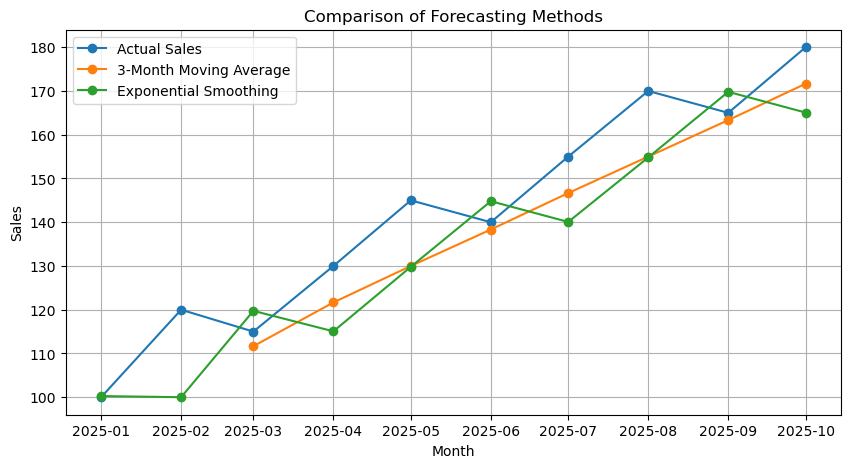

In [7]:
# Practice Problem 4 — Compare Forecasting Methods

import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.holtwinters import SimpleExpSmoothing

# Create sales dataset
data = {
    "Month": pd.date_range(start="2025-01-01", periods=10, freq="MS"),
    "Sales": [100, 120, 115, 130, 145, 140, 155, 170, 165, 180]
}

df = pd.DataFrame(data)

print(df)

# -------------------------------
# 1. Moving Average Forecasting
# -------------------------------

window = 3

df["Moving_Average"] = df["Sales"].rolling(window=window).mean()

# Forecast next month using latest 3 observations
ma_forecast = df["Sales"].tail(window).mean()

print("\n3-Month Moving Average:")
print(df[["Month", "Sales", "Moving_Average"]])

print("\nMoving Average Forecast for next month:",
      round(ma_forecast, 2))

# -------------------------------
# 2. Simple Exponential Smoothing
# -------------------------------

model = SimpleExpSmoothing(
    df["Sales"],
    initialization_method="estimated"
)

fit = model.fit(optimized=True)

df["SES_Fitted"] = fit.fittedvalues

# Forecast next month
ses_forecast = fit.forecast(1)

print("\nSimple Exponential Smoothing:")
print(df[["Month", "Sales", "SES_Fitted"]])

print("\nSES Forecast for next month:",
      round(float(ses_forecast.iloc[0]), 2))

# -------------------------------
# 3. Compare the forecasts
# -------------------------------

print("\nForecast Comparison")
print("3-Month Moving Average:",
      round(ma_forecast, 2))

print("Simple Exponential Smoothing:",
      round(float(ses_forecast.iloc[0]), 2))

# Plot actual sales and both methods
plt.figure(figsize=(10, 5))
plt.plot(df["Month"], df["Sales"],
         marker="o", label="Actual Sales")
plt.plot(df["Month"], df["Moving_Average"],
         marker="o", label="3-Month Moving Average")
plt.plot(df["Month"], df["SES_Fitted"],
         marker="o", label="Exponential Smoothing")

plt.title("Comparison of Forecasting Methods")
plt.xlabel("Month")
plt.ylabel("Sales")
plt.legend()
plt.grid(True)
plt.show()

       Month  Sales
0 2025-01-01    100
1 2025-02-01    105
2 2025-03-01    110
3 2025-04-01    115
4 2025-05-01    120
5 2025-06-01    125
6 2025-07-01    180

3-Month Moving Average:
       Month  Sales  Moving_Average
0 2025-01-01    100             NaN
1 2025-02-01    105             NaN
2 2025-03-01    110      105.000000
3 2025-04-01    115      110.000000
4 2025-05-01    120      115.000000
5 2025-06-01    125      120.000000
6 2025-07-01    180      141.666667

Moving Average Forecast for next month: 141.67

Simple Exponential Smoothing:
       Month  Sales  SES_Fitted
0 2025-01-01    100       100.0
1 2025-02-01    105       100.0
2 2025-03-01    110       105.0
3 2025-04-01    115       110.0
4 2025-05-01    120       115.0
5 2025-06-01    125       120.0
6 2025-07-01    180       125.0

SES Forecast for next month: 180.0

Forecast Comparison
3-Month Moving Average: 141.67
Simple Exponential Smoothing: 180.0


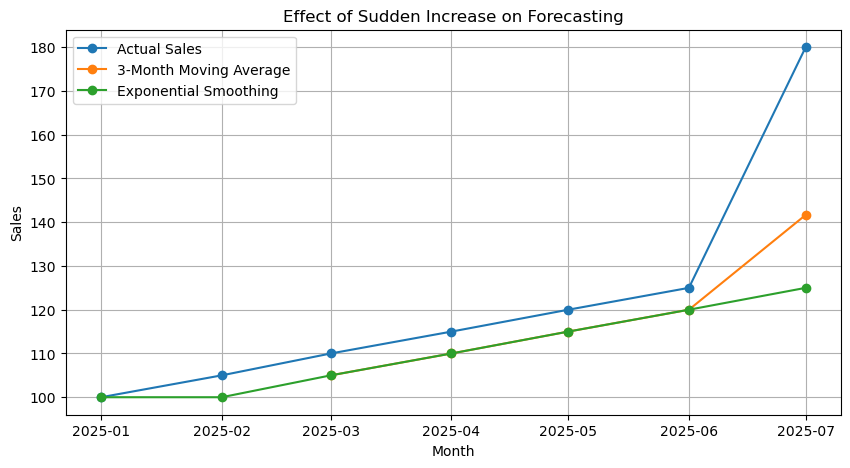

In [8]:
# Practice Problem 5 — Effect of Recent Changes

import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.holtwinters import SimpleExpSmoothing

# Create sales dataset
data = {
    "Month": pd.date_range(start="2025-01-01", periods=7, freq="MS"),
    "Sales": [100, 105, 110, 115, 120, 125, 180]
}

df = pd.DataFrame(data)

print(df)

# -------------------------------
# 1. Moving Average Forecasting
# -------------------------------

window = 3

df["Moving_Average"] = df["Sales"].rolling(window=window).mean()

# Forecast next month using latest 3 observations
ma_forecast = df["Sales"].tail(window).mean()

print("\n3-Month Moving Average:")
print(df[["Month", "Sales", "Moving_Average"]])

print("\nMoving Average Forecast for next month:",
      round(ma_forecast, 2))

# -------------------------------
# 2. Simple Exponential Smoothing
# -------------------------------

model = SimpleExpSmoothing(
    df["Sales"],
    initialization_method="estimated"
)

fit = model.fit(optimized=True)

df["SES_Fitted"] = fit.fittedvalues

# Forecast next month
ses_forecast = fit.forecast(1)

print("\nSimple Exponential Smoothing:")
print(df[["Month", "Sales", "SES_Fitted"]])

print("\nSES Forecast for next month:",
      round(float(ses_forecast.iloc[0]), 2))

# -------------------------------
# 3. Compare the methods
# -------------------------------

print("\nForecast Comparison")
print("3-Month Moving Average:",
      round(ma_forecast, 2))

print("Simple Exponential Smoothing:",
      round(float(ses_forecast.iloc[0]), 2))

# Plot actual sales and both methods
plt.figure(figsize=(10, 5))
plt.plot(df["Month"], df["Sales"],
         marker="o", label="Actual Sales")
plt.plot(df["Month"], df["Moving_Average"],
         marker="o", label="3-Month Moving Average")
plt.plot(df["Month"], df["SES_Fitted"],
         marker="o", label="Exponential Smoothing")

plt.title("Effect of Sudden Increase on Forecasting")
plt.xlabel("Month")
plt.ylabel("Sales")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# Practice Problem 6 — Real-World Dataset

import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.holtwinters import SimpleExpSmoothing

# Create a 24-month electricity demand dataset
data = {
    "Month": pd.date_range(start="2025-01-01", periods=24, freq="MS"),
    "Demand": [
        220, 225, 230, 235, 240, 245,
        250, 255, 260, 265, 270, 275,
        280, 285, 290, 295, 300, 305,
        310, 315, 320, 325, 330, 335
    ]
}

df = pd.DataFrame(data)

print(df)

# -------------------------------
# 1. 3-Month Moving Average
# -------------------------------

df["Moving_Average_3"] = df["Demand"].rolling(window=3).mean()

ma3_forecast = df["Demand"].tail(3).mean()

print("\n3-Month Moving Average:")
print(df[["Month", "Demand", "Moving_Average_3"]])

print("\n3-Month Moving Average Forecast for next month:",
      round(ma3_forecast, 2))

# -------------------------------
# 2. 6-Month Moving Average
# -------------------------------

df["Moving_Average_6"] = df["Demand"].rolling(window=6).mean()

ma6_forecast = df["Demand"].tail(6).mean()

print("\n6-Month Moving Average:")
print(df[["Month", "Demand", "Moving_Average_6"]])

print("\n6-Month Moving Average Forecast for next month:",
      round(ma6_forecast, 2))

# -------------------------------
# 3. Simple Exponential Smoothing
# -------------------------------

model = SimpleExpSmoothing(
    df["Demand"],
    initialization_method="estimated"
)

fit = model.fit(optimized=True)

df["SES_Fitted"] = fit.fittedvalues

ses_forecast = fit.forecast(1)

print("\nSimple Exponential Smoothing:")
print(df[["Month", "Demand", "SES_Fitted"]])

print("\nSES Forecast for next month:",
      round(float(ses_forecast.iloc[0]), 2))

# -------------------------------
# 4. Compare the Methods
# -------------------------------

print("\nForecast Comparison")
print("3-Month Moving Average:",
      round(ma3_forecast, 2))

print("6-Month Moving Average:",
      round(ma6_forecast, 2))

print("Simple Exponential Smoothing:",
      round(float(ses_forecast.iloc[0]), 2))

# -------------------------------
# 5. Plot the Results
# -------------------------------

plt.figure(figsize=(12, 6))

plt.plot(df["Month"], df["Demand"],
         marker="o", label="Actual Demand")

plt.plot(df["Month"], df["Moving_Average_3"],
         marker="o", label="3-Month Moving Average")

plt.plot(df["Month"], df["Moving_Average_6"],
         marker="o", label="6-Month Moving Average")

plt.plot(df["Month"], df["SES_Fitted"],
         marker="o", label="Exponential Smoothing")

plt.title("Comparison of Forecasting Methods")
plt.xlabel("Month")
plt.ylabel("Electricity Demand")
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

        Month  Demand
0  2025-01-01     220
1  2025-02-01     225
2  2025-03-01     230
3  2025-04-01     235
4  2025-05-01     240
5  2025-06-01     245
6  2025-07-01     250
7  2025-08-01     255
8  2025-09-01     260
9  2025-10-01     265
10 2025-11-01     270
11 2025-12-01     275
12 2026-01-01     280
13 2026-02-01     285
14 2026-03-01     290
15 2026-04-01     295
16 2026-05-01     300
17 2026-06-01     305
18 2026-07-01     310
19 2026-08-01     315
20 2026-09-01     320
21 2026-10-01     325
22 2026-11-01     330
23 2026-12-01     335

3-Month Moving Average:
        Month  Demand  Moving_Average_3
0  2025-01-01     220               NaN
1  2025-02-01     225               NaN
2  2025-03-01     230             225.0
3  2025-04-01     235             230.0
4  2025-05-01     240             235.0
5  2025-06-01     245             240.0
6  2025-07-01     250             245.0
7  2025-08-01     255             250.0
8  2025-09-01     260             255.0
9  2025-10-01     265    

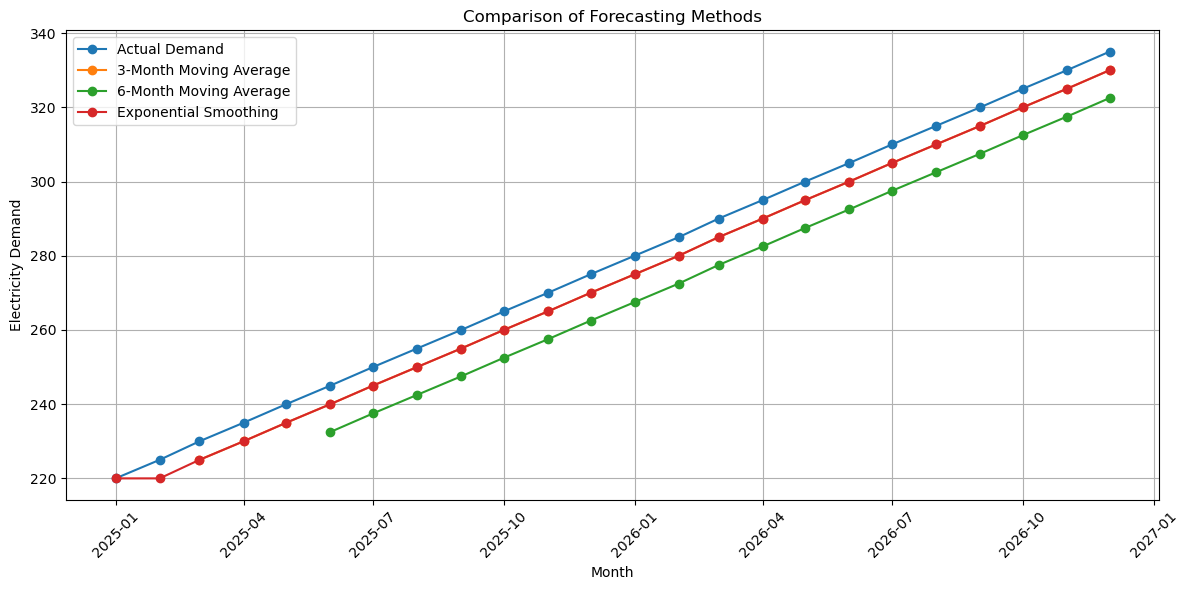